# Tugas Klasifikasi Teks — Sentimen Ulasan Aplikasi (Gojek, Shopee, Tokopedia)

**Nama:** Muhammad Daffa Raihan  
**NIM:** 25917045  
**Mata kuliah:** Text Analytics
**Repositori GitHub:** <https://github.com/Dffarhn2004/Analitik-Text-Ulasan-Aplikasi>

Notebook ini berisi Bagian 0–6: identifikasi masalah, pengumpulan data, pra-pemrosesan, rekayasa fitur (TF-IDF & Word2Vec), EDA, klasifikasi, dan soal teori.

## Bagian 0 — Identifikasi Masalah

**Artikel yang diangkat** (diunduh, terlampir di folder `article/`):
*"Fenomena ‘Krisis Ojol’ di Bulan Ramadan"*, RRI.co.id (Indepth), 14 Maret 2026.
Tautan: <https://rri.co.id/indepth/10776/fenomena-krisis-ojol-di-bulan-ramadan>
Berkas: `article/rri_krisis_ojol_ramadan.html` (halaman asli) dan `article/rri_krisis_ojol_ramadan.txt` (teks artikel).

**Isu yang diangkat.** Selama Ramadan 2026 pengguna aplikasi ojek daring ramai mengeluhkan sulit mendapatkan driver, terutama sore hari menjelang berbuka. Artikel memuat pengakuan pengguna yang harus memesan berulang kali, menunggu hingga hampir satu jam, atau pesanannya dibatalkan driver. Keluhan ini ramai di media sosial dan memunculkan istilah "krisis ojol".

**Mengapa ini masalah klasifikasi teks?** Keluhan pengguna tersebar dalam ribuan ulasan di toko aplikasi dan media sosial, sehingga membacanya satu per satu tidak praktis. Mengklasifikasikan ulasan menjadi **positif atau negatif (keluhan)** secara otomatis memungkinkan pengelola aplikasi, regulator, atau peneliti memantau lonjakan keluhan dan memprioritaskan ulasan negatif untuk ditindaklanjuti.

**Rancangan solusi.**

| Aspek | Rancangan |
|---|---|
| Tugas | Klasifikasi biner sentimen ulasan aplikasi: `negative` (keluhan) vs `positive` |
| Data | Ulasan Google Play untuk Gojek, Shopee, Tokopedia, Februari–Maret 2026 (Bagian 1) |
| Pra-pemrosesan | lowercase → hapus tanda baca/karakter khusus → normalisasi slang → tokenisasi → stopwords (negasi dipertahankan) → stemming Sastrawi |
| Fitur | TF-IDF (dasar klasifikasi) dan rata-rata vektor Word2Vec (pembanding) |
| Model | Naive Bayes, Logistic Regression, Linear SVM |
| Evaluasi | accuracy, precision, recall, F1 (kelas `negative` sebagai kelas perhatian) + macro-F1 + cross-validation |

> **Posisi klasifikasi sentimen dalam solusi.** Klasifikasi sentimen pada tugas ini adalah **tahap awal**, bukan solusi lengkap untuk isu artikel. Alur yang dibayangkan: (1) klasifier sentimen menyaring ulasan `negative` dari ribuan ulasan; (2) ulasan negatif dikelompokkan atau diklasifikasikan menurut topik (mis. "sulit dapat driver", "pembatalan oleh driver", "saldo") untuk melihat tema keluhan yang naik; (3) jumlah keluhan per tema dipantau menurut waktu. Tahap 2 dan 3 **tidak** dikerjakan di sini karena dataset tidak punya label topik; pada Bagian 6.3 hanya ada demonstrasi awal pengelompokan (K-means) yang menunjukkan satu klaster ulasan negatif bertema sulit dapat driver.
>
> **Batasan kecocokan data dengan artikel.** Dataset berisi ulasan umum tiga aplikasi (Gojek hanya sekitar sepertiga) pada 23 Feb–25 Mar 2026, bersinggungan dengan periode "krisis ojol" tetapi tidak dipilih khusus untuk isu itu. Model yang dilatih membedakan positif dan negatif, bukan mendeteksi keluhan ketersediaan driver.

## Bagian 1 — Pengumpulan Data

In [1]:
# Import pustaka yang dipakai di seluruh notebook
import os, re, json, io, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.25)   # font grafik lebih besar agar terbaca di laporan
RANDOM_STATE = 42   # supaya hasil dapat direproduksi

### 1.1 Deskripsi dataset

- **Nama / sumber:** `RimuruChan67/indonesian-googleplay-sentiment` di Hugging Face (<https://huggingface.co/datasets/RimuruChan67/indonesian-googleplay-sentiment>), berisi ulasan Google Play berbahasa Indonesia.
- **Dua konfigurasi:** `reviews` (5.336 ulasan, dipakai sebagai data utama) dan `manual_annotation` (496 ulasan yang dilabeli ulang manusia, dipakai untuk memeriksa kualitas label).
- **Fitur pada `reviews`:** `app` (Gojek/Shopee/Tokopedia), `review_text` (teks ulasan), `rating` (bintang), `review_date`, `label` (`positive`/`negative`), `split` (pembagian bawaan penyedia).
- **Target:** `label`. Penyedia tidak mendokumentasikan cara pelabelan pada kartu yang saya baca, sehingga kualitas label diperiksa pada Bagian 1.3.
- **Kualitas yang perlu dicatat:** ada teks duplikat dan sedikit label konflik (dibuang pada 1.3). Lisensi dan detail pengumpulan data tidak diverifikasi.

#### Kamus data (isi kolom dataset)

**Berkas `data/reviews.csv` — data utama (5.336 baris × 6 kolom):**

| Kolom | Tipe | Isi / arti | Nilai |
|---|---|---|---|
| `app` | teks (kategori) | Nama aplikasi yang diulas | Tokopedia 1.834, Gojek 1.782, Shopee 1.720 |
| `review_text` | teks | Isi ulasan pengguna di Google Play (tidak baku, ada slang, singkatan, emoji); panjang 6–500 karakter, rata-rata 94 | 5.179 teks unik |
| `rating` | bilangan bulat | Bintang yang diberikan pengguna | hanya 1, 2, 4, 5 (tidak ada 3): 1 = 2.370, 2 = 349, 4 = 246, 5 = 2.371 |
| `review_date` | teks (tanggal) | Tanggal ulasan | 23 Feb 2026 – 25 Mar 2026 (31 tanggal) |
| `label` | teks (kategori) | **Target klasifikasi** (sentimen ulasan) | negative 2.971, positive 2.365 |
| `split` | teks (kategori) | Pembagian data bawaan penyedia (tidak dipakai; kita membagi ulang 80/20) | train 3.627, test 1.068, validation 641 |

Tidak ada nilai kosong pada keenam kolom. Hubungan `rating` dan `label`: rating 1–2 hampir semuanya `negative`, rating 5 hampir semuanya `positive`, tetapi tidak identik (mis. 176 ulasan berating 5 berlabel `negative`, 84 ulasan berating 4 berlabel `negative`), sehingga label tidak sekadar turunan bintang.

**Berkas `data/manual_annotation.csv` — 496 ulasan untuk memeriksa label (496 baris × 6 kolom):**

| Kolom | Isi / arti |
|---|---|
| `review_text`, `app`, `rating` | Sama seperti di atas |
| `star_label` | Label sentimen dari penyedia (pada 496 ulasan ini identik dengan `label` di `reviews.csv`): negative 276, positive 220 |
| `human_label` | Label hasil anotasi manusia: negative 303, positive 193 |
| `agreement` | `agree` jika `star_label` = `human_label` (467 ulasan), `disagree` jika berbeda (29 ulasan) |

Pada Bagian 1.3 `human_label` dipakai sebagai pembanding untuk menghitung kesesuaian label (94,2%). Kolom yang dipakai untuk model hanya `review_text` (fitur) dan `label` (target); `app` dipakai untuk EDA.

In [2]:
# Kode pengumpulan data: unduh dari Hugging Face (datasets-server) bila berkas lokal belum ada
os.makedirs("data", exist_ok=True)
if not (os.path.exists("data/reviews.csv") and os.path.exists("data/manual_annotation.csv")):
    API = "https://datasets-server.huggingface.co/parquet?dataset=RimuruChan67/indonesian-googleplay-sentiment"
    req = lambda url: urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=120)
    for f in json.load(req(API))["parquet_files"]:
        d = pd.read_parquet(io.BytesIO(req(f["url"]).read()))
        d.to_csv(f"data/{f['config']}.csv", index=False, encoding="utf-8")

reviews = pd.read_csv("data/reviews.csv")
manual = pd.read_csv("data/manual_annotation.csv")
print("reviews          :", reviews.shape, list(reviews.columns))
print("manual_annotation:", manual.shape, list(manual.columns))

reviews          : (5336, 6) ['app', 'review_text', 'rating', 'review_date', 'label', 'split']
manual_annotation: (496, 6) ['review_text', 'app', 'rating', 'star_label', 'human_label', 'agreement']


In [3]:
# Kamus data otomatis: tipe, jumlah nilai unik, nilai kosong, dan contoh tiap kolom
def kamus(d):
    return pd.DataFrame({"tipe": d.dtypes.astype(str), "nilai_unik": d.nunique(), "kosong": d.isna().sum(),
                         "contoh": d.iloc[0].astype(str).str[:45]})
print("reviews:");           print(kamus(reviews).to_string())
print("\nmanual_annotation:"); print(kamus(manual).to_string())

reviews:
              tipe  nilai_unik  kosong                                         contoh
app            str           3       0                                          Gojek
review_text    str        5179       0  Gilak dari pagi sampai sekarang nyari driver 
rating       int64           4       0                                              1
review_date    str          31       0                                     2026-03-25
label          str           2       0                                       negative
split          str           3       0                                          train

manual_annotation:
              tipe  nilai_unik  kosong          contoh
review_text    str         494       0  ilove u tokped
app            str           3       0       Tokopedia
rating       int64           4       0               5
star_label     str           2       0        positive
human_label    str           2       0        positive
agreement      str           2       0 

### 1.2 Ringkasan dataset mentah

In [4]:
print("Periode ulasan :", reviews["review_date"].min(), "s.d.", reviews["review_date"].max())
print("\nJumlah per aplikasi dan label:")
print(reviews.groupby(["app", "label"]).size().unstack())
print("\nRating:", reviews["rating"].value_counts().sort_index().to_dict())
print("Teks duplikat:", reviews["review_text"].duplicated().sum(), "| missing:", int(reviews[["review_text", "label"]].isna().sum().sum()))
print("\nContoh ulasan:")
display(reviews.sample(6, random_state=1)[["app", "review_text", "rating", "label"]])

Periode ulasan : 2026-02-23 s.d. 2026-03-25

Jumlah per aplikasi dan label:
label      negative  positive
app                          
Gojek          1128       654
Shopee          705      1015
Tokopedia      1138       696

Rating: {1: 2370, 2: 349, 4: 246, 5: 2371}
Teks duplikat: 157 | missing: 0

Contoh ulasan:


,app,review_text,rating,label
1660,Gojek,susah dapat driver sekarang.,1,negative
2385,Tokopedia,Mulai hari ini Tokopedia banyak bugnya sehingg...,4,negative
5233,Shopee,makin mantap 👍,5,positive
1956,Tokopedia,Cuatomer Servis terburuk,1,negative
1881,Tokopedia,eh kebiasaan top up saldo etoll... sebelum bay...,1,negative
1297,Gojek,"susah dapet penumpang, kebanyakan ambil untung...",1,negative


### 1.3 Pembersihan data dan pemeriksaan kualitas label

In [5]:
# Teks identik dengan label berbeda tidak bisa dipercaya: buang seluruhnya
n_lbl = reviews.groupby("review_text")["label"].nunique()
conflict_texts = n_lbl[n_lbl > 1].index
print("Teks dengan label konflik:", len(conflict_texts))
df = reviews[~reviews["review_text"].isin(conflict_texts)]

# Buang duplikat agar data uji tidak memuat salinan data latih (data leakage)
df = df.drop_duplicates(subset="review_text").reset_index(drop=True)
df = df.rename(columns={"review_text": "text"})
print("Setelah pembersihan:", df.shape)
print(df["label"].value_counts().to_frame("jumlah").assign(persen=lambda x: (100*x.jumlah/x.jumlah.sum()).round(1)))

# Kualitas label: bandingkan kolom `label` dengan anotasi manusia pada 496 ulasan
chk = manual.merge(reviews.drop_duplicates("review_text")[["review_text", "label"]], on="review_text")
print("\nUlasan beranotasi manusia yang bisa dicocokkan:", len(chk))
print("Kesesuaian `label` dengan anotasi manusia: %.1f%%" % (100 * (chk["label"] == chk["human_label"]).mean()))

Teks dengan label konflik: 2
Setelah pembersihan: (5177, 6)
          jumlah  persen
label                   
negative    2960    57.2
positive    2217    42.8



Ulasan beranotasi manusia yang bisa dicocokkan: 496
Kesesuaian `label` dengan anotasi manusia: 94.2%


## Bagian 2 — Pra-pemrosesan Teks

Urutan penerapan:

1. **Lowercasing** — menyamakan "Bagus" dan "bagus".
2. **Penghapusan tanda baca & karakter khusus** (URL, angka, emoji, simbol) dan pemadatan huruf berulang ("baguuus" → "bagus").
3. **Normalisasi slang** — ulasan berbahasa tidak baku, sehingga sejumlah singkatan umum diseragamkan (`gk/ga/nggak` → `tidak`, `bgt` → `banget`, dst.). Kamus ini kecil dan dibuat manual; belum mencakup semua slang.
4. **Tokenisasi** — memecah teks menjadi token kata.
5. **Penghapusan stopwords** — daftar stopwords NLTK bahasa Indonesia, **kecuali kata negasi** (`tidak`, `bukan`, `belum`, `jangan`, ...) karena membalik makna sentimen ("tidak bagus").
6. **Stemming** — Sastrawi (stemmer bahasa Indonesia berbasis aturan); hasil di-*cache* per kata agar cepat.

In [6]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

for pkg in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

NEGATIONS = {"tidak", "tak", "bukan", "belum", "jangan", "tanpa", "nggak", "ga", "gak"}
STOPWORDS = set(stopwords.words("indonesian")) - NEGATIONS
STEMMER = StemmerFactory().create_stemmer()

# Kamus normalisasi slang (kecil, manual)
SLANG = {"gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak", "ngga": "tidak", "tdk": "tidak",
         "tak": "tidak", "bgt": "banget", "bngt": "banget", "yg": "yang", "dgn": "dengan", "dg": "dengan",
         "udh": "sudah", "udah": "sudah", "sdh": "sudah", "blm": "belum", "jg": "juga", "krn": "karena",
         "utk": "untuk", "tp": "tapi", "trs": "terus", "aja": "saja", "kok": "kok", "bs": "bisa",
         "gabisa": "tidak bisa", "gbs": "tidak bisa", "sy": "saya", "gue": "saya", "gw": "saya",
         "brp": "berapa", "dr": "dari", "skrg": "sekarang", "emg": "memang", "lg": "lagi", "lgi": "lagi",
         "kpn": "kapan", "knp": "kenapa", "bkn": "bukan", "jgn": "jangan", "pake": "pakai", "bagusss": "bagus"}

_stem_cache = {}
def stem(w):
    if w not in _stem_cache:
        _stem_cache[w] = STEMMER.stem(w)
    return _stem_cache[w]

def preprocess(text, return_steps=False, stopword_set=None):
    sw = STOPWORDS if stopword_set is None else stopword_set
    # a) lowercasing
    t = str(text).lower()
    # b) hapus URL, lalu semua yang bukan huruf; padatkan huruf berulang >2 kali
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"(.)\1{2,}", r"\1", t)
    t = re.sub(r"\s+", " ", t).strip()
    # c) normalisasi slang (per token), lalu d) tokenisasi
    t = " ".join(SLANG.get(w, w) for w in t.split())
    tokens = word_tokenize(t)
    # e) stopwords (negasi dipertahankan) dan token 1 huruf
    no_stop = [w for w in tokens if w not in sw and len(w) > 1]
    # f) stemming
    stems = [stem(w) for w in no_stop]
    if return_steps:
        return dict(lower_clean=t, tokens=tokens, no_stopwords=no_stop, stemmed=stems)
    return " ".join(stems)

df["clean"] = df["text"].apply(preprocess)
df["tokens"] = df["clean"].str.split()
print("Ulasan kosong setelah pra-pemrosesan:", (df["tokens"].str.len() == 0).sum())

Ulasan kosong setelah pra-pemrosesan: 17


### 2.2 Contoh sebelum dan sesudah pra-pemrosesan

In [7]:
sample = df.loc[df["text"].str.len().between(80, 160), "text"].iloc[0]
steps = preprocess(sample, return_steps=True)
print("TEKS ASLI            :", sample, "\n")
print("Lower + bersih + slang:", steps["lower_clean"], "\n")
print("Token                :", steps["tokens"])
print("Tanpa stopwords      :", steps["no_stopwords"])
print("Stemming             :", steps["stemmed"])

pd.DataFrame({"sebelum": df["text"].head(5).values, "sesudah": df["clean"].head(5).values})

TEKS ASLI            : driver gocar libur lebaran pada betingkah semua gak mau nerima order giliran hari biasa ngeluh sepi susah dapet order payah 

Lower + bersih + slang: driver gocar libur lebaran pada betingkah semua tidak mau nerima order giliran hari biasa ngeluh sepi susah dapet order payah 

Token                : ['driver', 'gocar', 'libur', 'lebaran', 'pada', 'betingkah', 'semua', 'tidak', 'mau', 'nerima', 'order', 'giliran', 'hari', 'biasa', 'ngeluh', 'sepi', 'susah', 'dapet', 'order', 'payah']
Tanpa stopwords      : ['driver', 'gocar', 'libur', 'lebaran', 'betingkah', 'tidak', 'nerima', 'order', 'giliran', 'ngeluh', 'sepi', 'susah', 'dapet', 'order', 'payah']
Stemming             : ['driver', 'gocar', 'libur', 'lebaran', 'beting', 'tidak', 'nerima', 'order', 'gilir', 'ngeluh', 'sepi', 'susah', 'dapet', 'order', 'payah']


,sebelum,sesudah
0,Gilak dari pagi sampai sekarang nyari driver n...,gilak pagi nyari driver nya susah go ride hema...
1,nunggu lama,nunggu
2,order gocar di batalkan tapi saldo tetap terpo...,order gocar batal saldo potong tidak refund
3,semakin lama semakin jelek pollll... driver se...,jelek pol driver ngelunjak diam ngelunjak kalo...
4,SIIIP aplk nya,sip aplk nya


In [8]:
# Buang ulasan yang kosong setelah pra-pemrosesan (tidak punya fitur)
df = df[df["tokens"].str.len() > 0].reset_index(drop=True)
print("Jumlah ulasan dipakai:", len(df))

Jumlah ulasan dipakai: 5160


## Bagian 3 — Rekayasa Fitur

### 3.1 TF-IDF

**Konsep.** TF-IDF memberi bobot pada kata *t* dalam dokumen *d*:
$\text{tfidf}(t,d)=\text{tf}(t,d)\times \text{idf}(t)$, dengan $\text{idf}(t)=\ln\frac{1+N}{1+df(t)}+1$ (rumus smoothing pada scikit-learn; *N* = jumlah dokumen, *df(t)* = jumlah dokumen yang memuat *t*).
- **TF** (term frequency): seberapa sering kata muncul di dokumen itu. Pada demonstrasi ini TF = jumlah kemunculan mentah. **Pada klasifikasi (Bagian 5) dipakai `sublinear_tf=True`**, yaitu $\text{tf}(t,d)=1+\ln(\text{jumlah kemunculan})$ untuk kata yang muncul, agar kata yang diulang banyak kali tidak mendominasi.
- **IDF** (inverse document frequency): kata yang muncul di hampir semua dokumen diberi bobot kecil, kata yang jarang tetapi khas diberi bobot besar.
Setiap vektor dokumen kemudian dinormalisasi (norma L2 = 1, bawaan scikit-learn). Hasilnya vektor jarang (*sparse*) berdimensi sebesar kosakata. Pada klasifikasi (Bagian 5) vectorizer di-*fit* hanya pada data latih; di sini dibuat pada seluruh korpus hanya untuk demonstrasi representasi.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_demo = TfidfVectorizer(min_df=2, max_df=0.95)
X_demo = tfidf_demo.fit_transform(df["clean"])
print("Bentuk matriks TF-IDF :", X_demo.shape, "(dokumen × kosakata)")
print("Kepadatan             : %.2f%%" % (100 * X_demo.nnz / np.prod(X_demo.shape)))

# Kata dengan bobot TF-IDF tertinggi pada ulasan pertama
terms = np.array(tfidf_demo.get_feature_names_out())
row = X_demo[0].toarray().ravel()
top = row.argsort()[::-1][:8]
print("\nUlasan:", df["text"].iloc[0])
pd.DataFrame({"kata": terms[top], "bobot_tfidf": row[top].round(4)})

Bentuk matriks TF-IDF : (5160, 2341) (dokumen × kosakata)
Kepadatan             : 0.34%

Ulasan: Gilak dari pagi sampai sekarang nyari driver nya susah, mau go ride hemat maupun biasa. ini sekarang nunggu in satu jam lebih buat nyari driver, udah berkali-kali aku cancel tetap ga dapet driver. gokilllll.... padahal banyak driver terdekat loh yah


,kata,bobot_tfidf
0,driver,0.4024
1,nyari,0.3456
2,kali,0.2860
3,gokil,0.2643
4,gilak,0.2582
5,ride,0.2380
6,pagi,0.2351
7,dekat,0.2324


### 3.2 Word2Vec

**Konsep.** Word2Vec (Mikolov dkk., 2013) mempelajari vektor padat berdimensi rendah untuk tiap kata memakai jaringan saraf dangkal yang memprediksi kata dari konteksnya (**CBOW**) atau konteks dari sebuah kata (**Skip-gram**). Kata yang muncul pada konteks serupa mendapat vektor yang berdekatan, sehingga kemiripan makna tertangkap, berbeda dengan TF-IDF yang memperlakukan tiap kata berdiri sendiri. Vektor dokumen dibentuk dengan merata-ratakan vektor kata-katanya.
Korpus kita pendek dan kecil (±5 ribu ulasan, rata-rata sekitar 15 kata), sehingga mutu embedding terbatas.

In [10]:
from gensim.models import Word2Vec

# Skip-gram (sg=1) pada token hasil pra-pemrosesan seluruh korpus (demonstrasi)
w2v_demo = Word2Vec(sentences=df["tokens"].tolist(), vector_size=100, window=5,
                    min_count=3, sg=1, epochs=30, seed=RANDOM_STATE, workers=1)
print("Ukuran kosakata Word2Vec:", len(w2v_demo.wv), "| Dimensi vektor:", w2v_demo.wv.vector_size)

for w in ["driver", "bagus", "lambat", "saldo", "iklan"]:
    if w in w2v_demo.wv:
        print(f"\nMirip '{w}':", [(k, round(s, 2)) for k, s in w2v_demo.wv.most_similar(w, topn=6)])

Ukuran kosakata Word2Vec: 1734 | Dimensi vektor: 100

Mirip 'driver': [('drivernya', 0.7), ('dpet', 0.68), ('kondisi', 0.68), ('ngebatalin', 0.68), ('rider', 0.66), ('kemudi', 0.66)]

Mirip 'bagus': [('ngelek', 0.75), ('ragu', 0.68), ('ok', 0.67), ('mantep', 0.67), ('debes', 0.65), ('komplit', 0.64)]

Mirip 'lambat': [('klu', 0.61), ('bangt', 0.56), ('pecah', 0.53), ('alam', 0.53), ('model', 0.52), ('bangat', 0.52)]

Mirip 'saldo': [('mandiri', 0.6), ('cukup', 0.59), ('bca', 0.59), ('rekening', 0.58), ('refund', 0.57), ('pemberitahuan', 0.56)]

Mirip 'iklan': [('rangin', 0.68), ('nonton', 0.64), ('ganggu', 0.62), ('maksa', 0.61), ('spam', 0.61), ('iklanya', 0.61)]


## Bagian 4 — Analisis Data Eksploratif (EDA) dan Visualisasi

In [11]:
from collections import Counter
from wordcloud import WordCloud

df["n_words_raw"] = df["text"].str.split().str.len()   # panjang sebelum pra-pemrosesan
df["n_words"] = df["tokens"].str.len()                  # panjang setelah pra-pemrosesan
print(df[["n_words_raw", "n_words"]].describe().round(1))

       n_words_raw  n_words
count       5160.0   5160.0
mean          15.4      9.7
std           16.2      9.7
min            1.0      1.0
25%            4.0      3.0
50%            9.0      6.0
75%           20.0     13.0
max           96.0     75.0


### 4.1 Word cloud (per kelas)

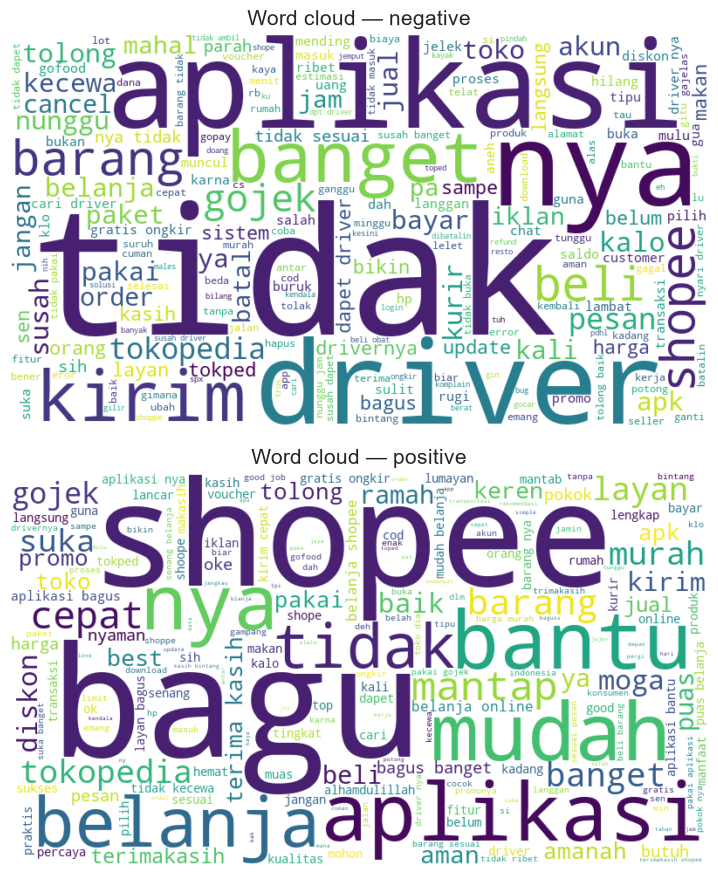

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))
for ax, lbl in zip(axes, ["negative", "positive"]):
    text = " ".join(df.loc[df.label == lbl, "clean"])
    wc = WordCloud(width=800, height=450, background_color="white", colormap="viridis",
                   random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"Word cloud — {lbl}")
plt.tight_layout(); plt.show()

### 4.2 Distribusi panjang teks (jumlah kata per dokumen)

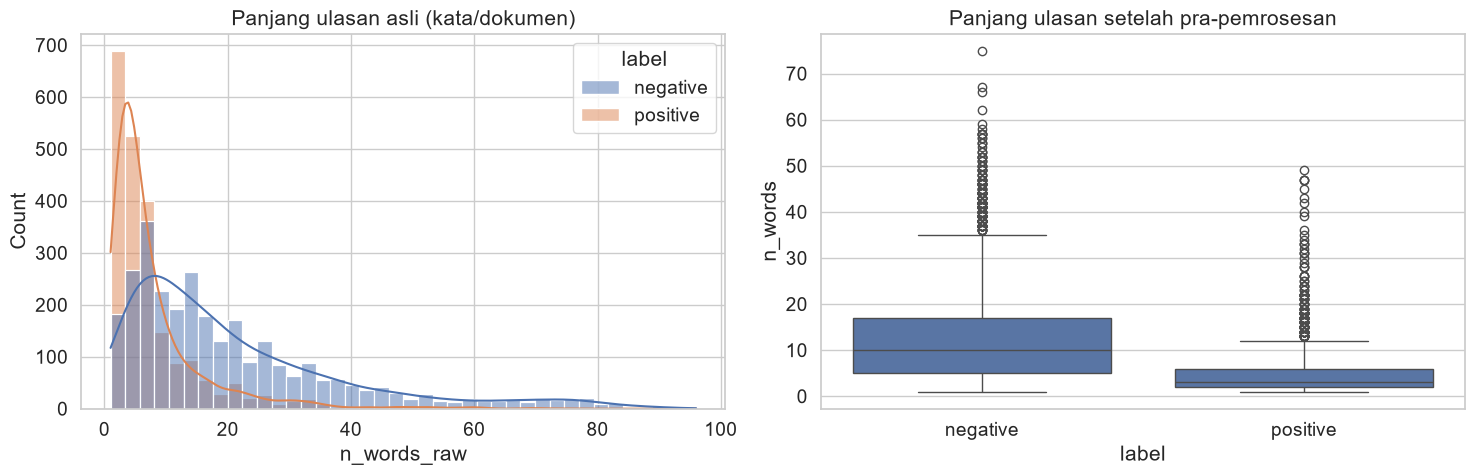

          n_words_raw  n_words
label                         
negative         15.0     10.0
positive          5.0      3.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df, x="n_words_raw", hue="label", bins=40, kde=True, ax=axes[0])
axes[0].set_title("Panjang ulasan asli (kata/dokumen)")
sns.boxplot(df, x="label", y="n_words", ax=axes[1])
axes[1].set_title("Panjang ulasan setelah pra-pemrosesan")
plt.tight_layout(); plt.show()
print(df.groupby("label")[["n_words_raw", "n_words"]].median())

### 4.3 Frekuensi kata teratas (bar plot)

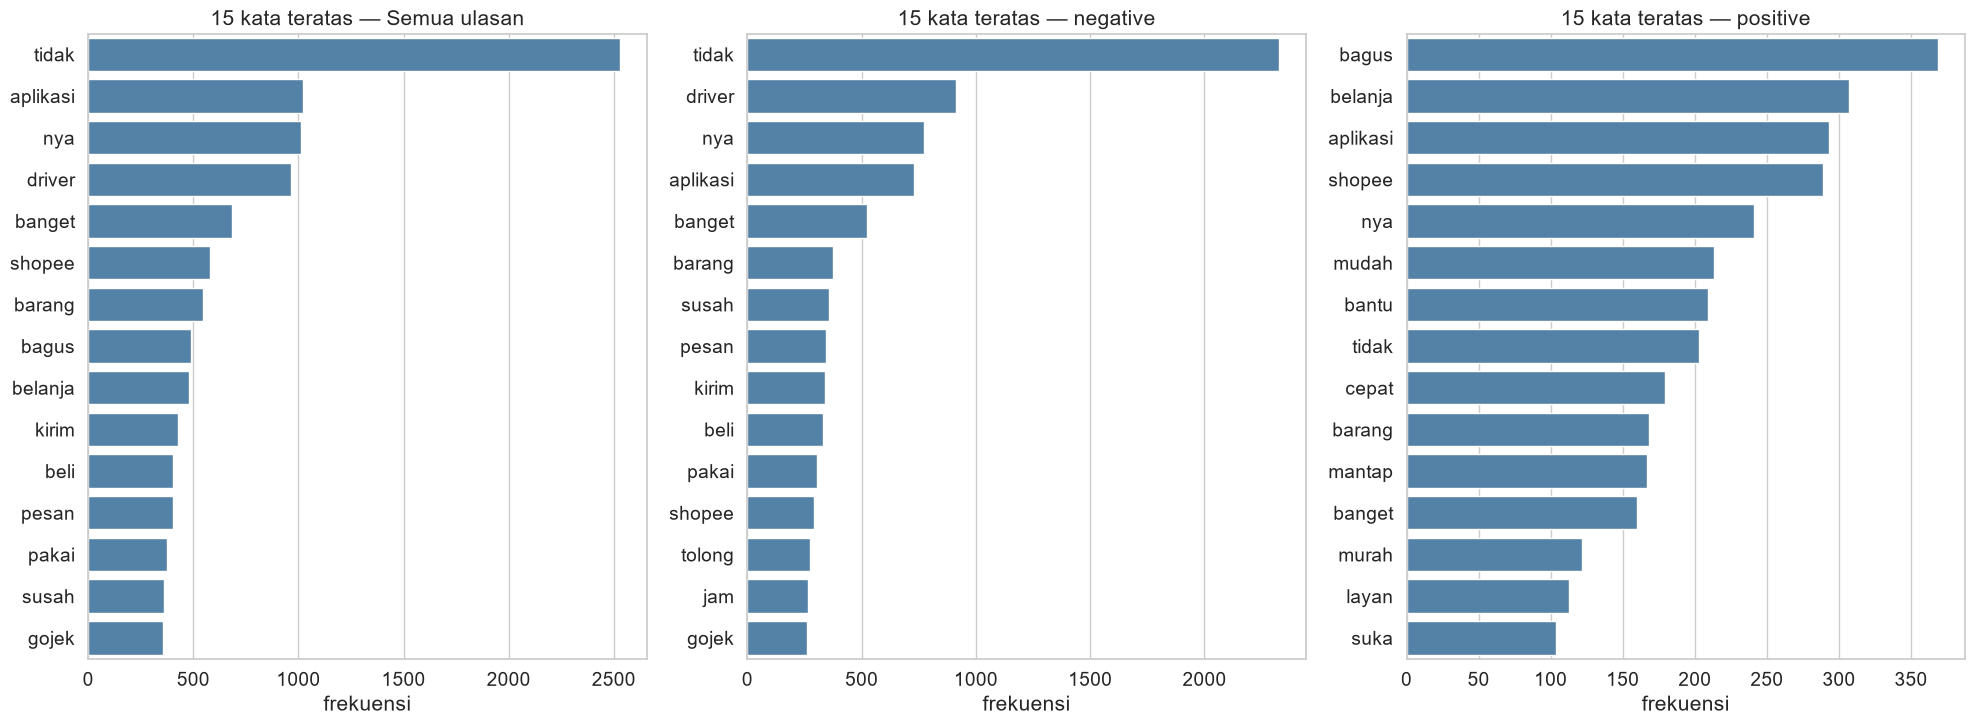

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7.5))
sets = [("Semua ulasan", df["tokens"]), ("negative", df.loc[df.label == "negative", "tokens"]),
        ("positive", df.loc[df.label == "positive", "tokens"])]
for ax, (title, toks) in zip(axes, sets):
    cnt = Counter(w for doc in toks for w in doc).most_common(15)
    words, freqs = zip(*cnt)
    sns.barplot(x=list(freqs), y=list(words), ax=ax, color="steelblue")
    ax.set_title(f"15 kata teratas — {title}"); ax.set_xlabel("frekuensi")
plt.tight_layout(); plt.show()

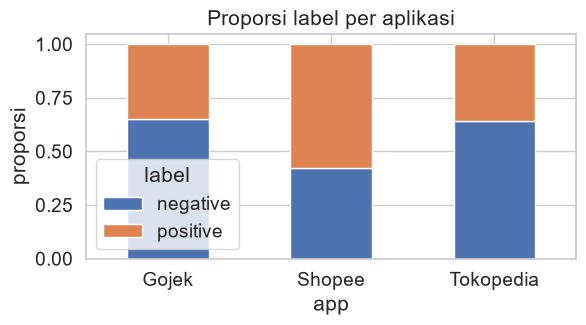

In [15]:
# Tambahan EDA: proporsi keluhan per aplikasi
(df.groupby("app")["label"].value_counts(normalize=True).unstack().round(3)
   .plot(kind="bar", stacked=True, figsize=(6, 3.5), rot=0, title="Proporsi label per aplikasi"))
plt.ylabel("proporsi"); plt.tight_layout(); plt.show()

**Catatan temuan EDA.** Bandingkan kata teratas kelas `negative` dan `positive` serta panjang ulasan keduanya. Perbedaan proporsi keluhan antar aplikasi menunjukkan bahwa `app` itu sendiri berkaitan dengan label (aplikasi berbeda, pengguna dan periode berbeda), sehingga skor model pada satu campuran aplikasi belum tentu berlaku untuk aplikasi lain.

## Bagian 5 — Klasifikasi Teks

**Rancangan eksperimen**

- Data dibagi **80% latih / 20% uji** secara *stratified* (`random_state=42`). Pembagian bawaan penyedia (`split`) tidak dipakai karena duplikat sudah dibuang dan pembagian sendiri diminta soal.
- TF-IDF di-*fit* **hanya pada data latih** di dalam `Pipeline` agar tidak ada kebocoran dari data uji.
- Tiga classifier pada fitur TF-IDF: **Multinomial Naive Bayes**, **Logistic Regression**, **Linear SVM**.
- Pembanding: Logistic Regression pada **rata-rata vektor Word2Vec** (Word2Vec dilatih hanya pada data latih).
- Kelas perhatian = `negative` (keluhan, label 1). Metrik: accuracy, precision, recall, F1 kelas tersebut, plus macro-F1; ditambah 5-fold cross-validation pada data latih.

In [16]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# a) Pisahkan data latih dan uji (80/20, stratified)
y = (df["label"] == "negative").astype(int)       # 1 = negative (keluhan), 0 = positive
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Latih:", len(X_train), "| Uji:", len(X_test))
print("Proporsi negative latih/uji: %.3f / %.3f" % (y_train.mean(), y_test.mean()))

Latih: 4128 | Uji: 1032
Proporsi negative latih/uji: 0.573 / 0.574


In [17]:
# b) Latih classifier pada data latih
def make_tfidf():
    return TfidfVectorizer(min_df=2, max_df=0.95, ngram_range=(1, 2), sublinear_tf=True)

models = {
    "Naive Bayes":         MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=10, random_state=RANDOM_STATE),
    "Linear SVM":          LinearSVC(C=1.0, random_state=RANDOM_STATE),
}
pipes = {n: Pipeline([("tfidf", make_tfidf()), ("clf", m)]).fit(X_train, y_train)
         for n, m in models.items()}

# c) Evaluasi pada data uji
def metrics(y_true, y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred),
                Precision=precision_score(y_true, y_pred),
                Recall=recall_score(y_true, y_pred),
                F1=f1_score(y_true, y_pred),
                **{"Macro-F1": f1_score(y_true, y_pred, average="macro")})

rows = {f"TF-IDF + {n}": metrics(y_test, p.predict(X_test)) for n, p in pipes.items()}

### 5.2 Pembanding: rata-rata vektor Word2Vec + Logistic Regression

In [18]:
# Word2Vec dilatih HANYA pada data latih
train_tokens = [t.split() for t in X_train]
w2v = Word2Vec(train_tokens, vector_size=100, window=5, min_count=2, sg=1,
               epochs=30, seed=RANDOM_STATE, workers=1)

def doc_vec(text):
    # rata-rata vektor kata yang ada di kosakata; nol jika tidak ada
    vecs = [w2v.wv[w] for w in text.split() if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

Xw_train = np.vstack([doc_vec(t) for t in X_train])
Xw_test  = np.vstack([doc_vec(t) for t in X_test])
lr_w2v = LogisticRegression(max_iter=2000, C=10, random_state=RANDOM_STATE).fit(Xw_train, y_train)
rows["Word2Vec(avg) + Logistic Regression"] = metrics(y_test, lr_w2v.predict(Xw_test))

### 5.3 Hasil evaluasi pada data uji

In [19]:
results = pd.DataFrame(rows).T.round(4)
display(results)

# Cross-validation 5-fold (F1 kelas negative) pada data latih sebagai pemeriksaan kestabilan
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {n: cross_val_score(Pipeline([("tfidf", make_tfidf()), ("clf", m)]),
                              X_train, y_train, cv=cv, scoring="f1")
           for n, m in models.items()}
print("\nF1 5-fold CV (data latih):")
display(pd.DataFrame({n: [s.mean(), s.std()] for n, s in cv_rows.items()}, index=["mean", "std"]).T.round(4))

,Accuracy,Precision,Recall,F1,Macro-F1
TF-IDF + Naive Bayes,0.8983,0.8684,0.9696,0.9162,0.8934
TF-IDF + Logistic Regression,0.9128,0.9010,0.9527,0.9261,0.9099
TF-IDF + Linear SVM,0.9089,0.8965,0.9510,0.9230,0.9058
Word2Vec(avg) + Logistic Regression,0.9118,0.8896,0.9662,0.9263,0.9083



F1 5-fold CV (data latih):


,mean,std
Naive Bayes,0.9214,0.0083
Logistic Regression,0.9282,0.0047
Linear SVM,0.9263,0.0046


Model terbaik (F1 uji): Word2Vec(avg) + Logistic Regression 

              precision    recall  f1-score   support

    positive      0.949     0.839     0.890       440
    negative      0.890     0.966     0.926       592

    accuracy                          0.912      1032
   macro avg      0.919     0.902     0.908      1032
weighted avg      0.915     0.912     0.911      1032



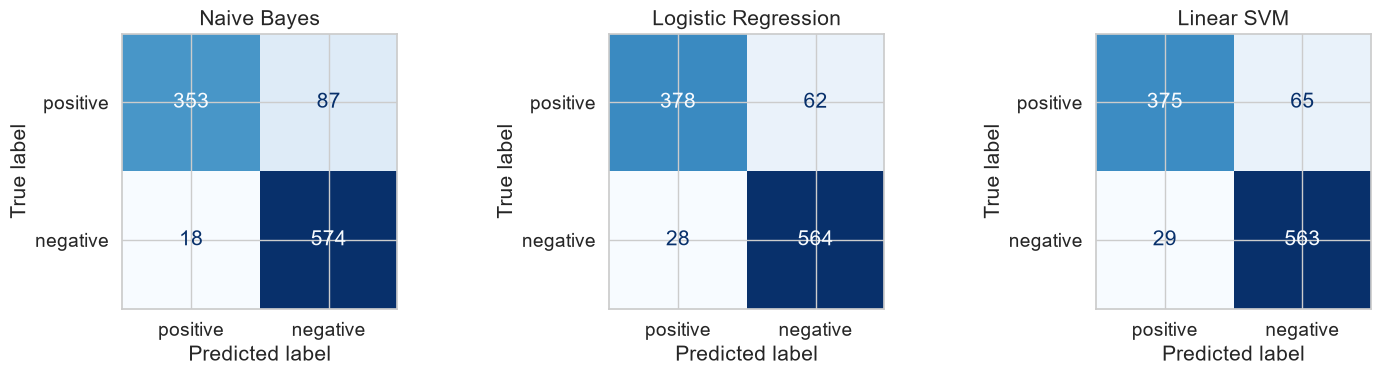

In [20]:
best = results["F1"].idxmax()
print("Model terbaik (F1 uji):", best, "\n")
best_pred = (pipes[best.replace("TF-IDF + ", "")].predict(X_test) if best.startswith("TF-IDF")
             else lr_w2v.predict(Xw_test))
print(classification_report(y_test, best_pred, target_names=["positive", "negative"], digits=3))

fig, axes = plt.subplots(1, len(pipes), figsize=(5*len(pipes), 4))
for ax, (n, p) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p.predict(X_test), display_labels=["positive", "negative"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()

In [21]:
# Kata paling berpengaruh menurut Logistic Regression (koefisien terbesar)
vec = pipes["Logistic Regression"].named_steps["tfidf"]
coef = pipes["Logistic Regression"].named_steps["clf"].coef_[0]
names = np.array(vec.get_feature_names_out())
order = coef.argsort()
print("Penciri positive:", list(names[order[:15]]))
print("Penciri negative:", list(names[order[::-1][:15]]))

# Contoh kesalahan model terbaik pada data uji
err = pd.DataFrame({"text": df.loc[X_test.index, "text"], "app": df.loc[X_test.index, "app"],
                    "rating": df.loc[X_test.index, "rating"], "benar": y_test.map({0: "positive", 1: "negative"}),
                    "prediksi": pd.Series(best_pred, index=X_test.index).map({0: "positive", 1: "negative"})})
print("\nContoh kesalahan prediksi:")
display(err[err.benar != err.prediksi].head(8))

Penciri positive: ['mudah', 'tidak kecewa', 'bagus', 'cepat', 'mantap', 'puas', 'ramah', 'oke', 'alhamdulillah', 'murah', 'bagus banget', 'senang', 'tidak ribet', 'keren', 'makasih']
Penciri negative: ['tidak', 'susah', 'mahal', 'buruk', 'sulit', 'bug', 'gagal', 'lot', 'jelek', 'lambat', 'cancel', 'nunggu', 'mending', 'parah', 'driver']

Contoh kesalahan prediksi:


,text,app,rating,benar,prediksi
4679,bintang 4 soal nya yang dimasukin keranjang su...,Shopee,4,positive,negative
3285,"Dulu waktu jualan pulsa, paket data, token pas...",Tokopedia,4,positive,negative
4760,segitu aja dl,Shopee,4,positive,negative
584,gak ribet dan easy use,Gojek,5,positive,negative
906,makasi bgt pls yang uda ciptain gojek. jadi or...,Gojek,5,positive,negative
306,membantu tapi menyulitkan,Gojek,1,negative,positive
2023,"sy cumaa pake tokopedia,jadi tdk bisa membedka...",Tokopedia,4,positive,negative
1659,tepat lokasi,Gojek,5,positive,negative


### 5.5 Uji dampak stopwords yang bermakna (ablasi)

Pada Bagian 2 daftar stopwords NLTK ikut membuang kata seperti `bisa`, `guna`, `lama`, `baik`, `sangat`, `kurang`, yang pada ulasan membawa makna ("tidak bisa", "tidak guna", "nunggu lama"). Di sini dibandingkan dua varian pra-pemrosesan, **A** (daftar NLTK dikurangi negasi, dipakai di seluruh notebook) dan **B** (A ditambah pengecualian 14 kata di bawah), dengan pembagian data yang sama. Pemilihan varian dinilai dengan cross-validation pada data latih; data uji hanya dilaporkan, tidak dipakai memilih.

In [22]:
KEEP = {"baik", "kurang", "sangat", "sekali", "benar", "bisa", "dapat", "guna",
        "lama", "mau", "cukup", "terlalu", "paling", "masih"}   # kata bermakna yang dikecualikan dari stopwords
STOPWORDS_B = STOPWORDS - KEEP

# Varian B memakai fungsi pra-pemrosesan yang sama; hanya daftar stopwords yang berbeda
df["clean_B"] = df["text"].apply(lambda t: preprocess(t, stopword_set=STOPWORDS_B))
print("Ulasan kosong pada varian B:", (df["clean_B"].str.len() == 0).sum())
print("Contoh 'ga guna' -> A:", preprocess("aplikasi ga guna, ga bisa dipakai lama banget"),
      "| B:", preprocess("aplikasi ga guna, ga bisa dipakai lama banget", stopword_set=STOPWORDS_B))


Ulasan kosong pada varian B: 0
Contoh 'ga guna' -> A: aplikasi tidak tidak pakai banget | B: aplikasi tidak guna tidak bisa pakai lama banget


In [23]:
abl_rows, abl_pred = {}, {}
for var, col in [("A (stopwords NLTK)", "clean"), ("B (kata bermakna dipertahankan)", "clean_B")]:
    for mname in ["Logistic Regression", "Linear SVM"]:
        pipe = lambda: Pipeline([("tfidf", make_tfidf()), ("clf", models[mname].__class__(**models[mname].get_params()))])
        cvs = cross_val_score(pipe(), df.loc[X_train.index, col], y_train, cv=cv, scoring="f1")
        m_ = pipe().fit(df.loc[X_train.index, col], y_train)
        pred = m_.predict(df.loc[X_test.index, col]); abl_pred[(var[0], mname)] = pred
        abl_rows[f"{mname} — {var}"] = {"CV F1 (rata-rata)": cvs.mean(), "CV F1 (std)": cvs.std(),
            "Uji Accuracy": accuracy_score(y_test, pred), "Uji F1": f1_score(y_test, pred)}
abl = pd.DataFrame(abl_rows).T.round(4)
display(abl)


,CV F1 (rata-rata),CV F1 (std),Uji Accuracy,Uji F1
Logistic Regression — A (stopwords NLTK),0.9282,0.0047,0.9128,0.9261
Linear SVM — A (stopwords NLTK),0.9263,0.0046,0.9089,0.9230
Logistic Regression — B (kata bermakna dipertahankan),0.9309,0.0034,0.9167,0.9297
Linear SVM — B (kata bermakna dipertahankan),0.9291,0.0059,0.9186,0.9313


### 5.6 Uji signifikansi antarmodel dan selang kepercayaan

Selisih skor yang kecil belum tentu berarti. Dua alat dipakai pada data uji: (1) **uji McNemar eksak** untuk setiap pasang model (membandingkan ulasan yang salah diklasifikasi oleh satu model tetapi benar oleh model lain; hipotesis nol: kedua model memiliki tingkat kesalahan yang sama); (2) **selang kepercayaan 95% bootstrap** (1.000 resampel data uji) untuk F1 tiap model. Uji dilakukan pada pembagian data yang sama, sehingga hanya mengukur ketidakpastian akibat ukuran data uji (1.032 ulasan), bukan akibat pembagian data yang berbeda.

In [24]:
from scipy.stats import binomtest

preds = {f"TF-IDF + {n}": p.predict(X_test) for n, p in pipes.items()}
preds["Word2Vec(avg) + LR"] = lr_w2v.predict(Xw_test)
preds["TF-IDF + LR, varian B"] = abl_pred[("B", "Logistic Regression")]
yt = y_test.values

# (1) McNemar eksak untuk semua pasangan
mc = []
names = list(preds)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        ok_i, ok_j = preds[names[i]] == yt, preds[names[j]] == yt
        b, c = int((ok_i & ~ok_j).sum()), int((~ok_i & ok_j).sum())      # diskordan
        pv = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
        mc.append({"Model 1": names[i], "Model 2": names[j], "hanya M1 benar": b, "hanya M2 benar": c, "p-value": round(pv, 4)})
mc = pd.DataFrame(mc)
display(mc)
print("Pasangan dengan p < 0,05:", int((mc["p-value"] < 0.05).sum()), "dari", len(mc), "(tanpa koreksi uji berganda)")

# (2) Selang kepercayaan 95% bootstrap untuk F1
rng = np.random.default_rng(RANDOM_STATE)
boot = {n: [] for n in names}
for _ in range(1000):
    ix = rng.integers(0, len(yt), len(yt))
    for n in names:
        boot[n].append(f1_score(yt[ix], preds[n][ix]))
ci = pd.DataFrame({n: {"F1 uji": f1_score(yt, preds[n]), "CI95 bawah": np.percentile(b, 2.5), "CI95 atas": np.percentile(b, 97.5)}
                   for n, b in boot.items()}).T.round(4)
display(ci)


,Model 1,Model 2,hanya M1 benar,hanya M2 benar,p-value
0,TF-IDF + Naive Bayes,TF-IDF + Logistic Regression,18,33,0.0489
1,TF-IDF + Naive Bayes,TF-IDF + Linear SVM,22,33,0.1770
2,TF-IDF + Naive Bayes,Word2Vec(avg) + LR,24,38,0.0980
3,TF-IDF + Naive Bayes,"TF-IDF + LR, varian B",17,36,0.0127
4,TF-IDF + Logistic Regression,TF-IDF + Linear SVM,7,3,0.3438
5,TF-IDF + Logistic Regression,Word2Vec(avg) + LR,32,31,1.0000
6,TF-IDF + Logistic Regression,"TF-IDF + LR, varian B",6,10,0.4545
7,TF-IDF + Linear SVM,Word2Vec(avg) + LR,33,36,0.8099
8,TF-IDF + Linear SVM,"TF-IDF + LR, varian B",9,17,0.1686
9,Word2Vec(avg) + LR,"TF-IDF + LR, varian B",29,34,0.6147


Pasangan dengan p < 0,05: 2 dari 10 (tanpa koreksi uji berganda)


,F1 uji,CI95 bawah,CI95 atas
TF-IDF + Naive Bayes,0.9162,0.9009,0.9317
TF-IDF + Logistic Regression,0.9261,0.9103,0.9415
TF-IDF + Linear SVM,0.9230,0.9068,0.9385
Word2Vec(avg) + LR,0.9263,0.9109,0.9407
"TF-IDF + LR, varian B",0.9297,0.9157,0.9447


### 5.4 Interpretasi dan batasan

- **Hasil:** keempat model berada pada accuracy 0,90–0,91 dan F1 kelas `negative` 0,92–0,93 pada 1.032 data uji. Selang kepercayaan 95% bootstrap untuk F1 lebarnya sekitar ±1,5 poin dan saling tumpang tindih antarmodel (Bagian 5.6).
- **Perbandingan model:** pada uji McNemar, hanya 2 dari 10 pasangan yang p < 0,05 tanpa koreksi uji berganda (Naive Bayes vs Logistic Regression, p = 0,049; Naive Bayes vs Logistic Regression varian B, p = 0,013), dan tidak ada yang bertahan dengan koreksi Bonferroni (ambang sekitar 0,005). Antara Logistic Regression, Linear SVM, dan Word2Vec p ≥ 0,34. Jadi **belum ada bukti yang cukup untuk menyatakan satu model secara konsisten lebih unggul**; hanya ada indikasi lemah bahwa Naive Bayes sedikit lebih rendah. Hasil ini berasal dari satu pembagian data latih/uji.
- **Dampak stopwords bermakna (Bagian 5.5):** mempertahankan 14 kata bermakna (`bisa`, `guna`, `lama`, `baik`, dst.) menaikkan F1 cross-validation sebesar sekitar 0,003 dan F1 uji 0,004–0,008, searah pada kedua model, tetapi kenaikan itu masih dalam rentang simpangan baku dan tidak signifikan pada uji McNemar (Logistic Regression A vs B, p = 0,45). Varian B tidak merugikan dan lebih masuk akal secara bahasa sehingga layak dipakai pada pengembangan lanjutan; hasil utama notebook tetap memakai varian A agar konsisten.
- **Pola kesalahan:** recall kelas `negative` tinggi (0,95–0,97) tetapi recall `positive` sekitar 0,84, artinya model cenderung menebak keluhan. Banyak kesalahan berupa ulasan positif yang sangat pendek atau tidak baku ("gak ribet dan easy use", "tepat lokasi") dan ulasan campuran ("membantu tapi menyulitkan").
- **Kualitas label:** pada 496 ulasan beranotasi manusia, `label` sesuai manusia 94,2%, menandakan masih ada label yang meleset (sekitar 6% pada sampel itu). Angka ini hanya indikasi adanya derau label; bukan batas maksimum akurasi, karena anotasi manusia pun bisa berbeda-beda dan sampelnya kecil.
- **Penciri kata masuk akal:** positif — mudah, bagus, cepat, puas, ramah; negatif — susah, mahal, buruk, sulit, bug, gagal, lambat, cancel, nunggu. Satu penciri ("lot") adalah artefak stemming/slang dan tidak bermakna.
- **Batasan:** data hanya tiga aplikasi dalam satu bulan (23 Feb–25 Mar 2026); ulasan hampir kembar (bukan duplikat persis) tidak dibuang sehingga bisa sedikit menaikkan skor; kamus slang kecil dan manual; dan tugas ini adalah **sentimen**, bukan topik, sehingga belum mendeteksi khusus keluhan "sulit dapat driver" seperti pada artikel.

## Bagian 6 — Soal Teori

Rujukan ditulis dengan nama penulis dan tahun; daftar lengkapnya ada di *Daftar Referensi* pada akhir Bagian 6.

### 6.1 Perbedaan *text classification* dan *text clustering*

| Aspek | Text classification | Text clustering |
|---|---|---|
| Jenis pembelajaran | *Supervised* (diawasi) | *Unsupervised* (tanpa pengawasan) |
| Kategori | Sudah ditentukan sebelumnya | Tidak diketahui; ditemukan dari data |
| Data latih | Perlu dokumen berlabel | Tidak perlu label |
| Keluaran | Label kategori untuk dokumen baru | Pengelompokan dokumen berdasarkan kemiripan |
| Evaluasi | accuracy, precision, recall, F1 terhadap label | metrik internal (mis. silhouette, SSE) atau entropi/F-measure jika ada label acuan |
| Contoh | Ulasan positive vs negative (Bagian 5) | Mengelompokkan ulasan ke dalam tema keluhan tanpa label |

**Dukungan referensi.**
- **Sebastiani (2002), hlm. 2, Bagian 1 (Introduction), paragraf terakhir sebelum uraian organisasi makalah:** klasifikasi teks adalah penetapan dokumen ke himpunan kategori yang telah ditentukan, sedangkan pengidentifikasian himpunan kategori sekaligus pengelompokan dokumen ke dalamnya disebut *text clustering*.
- **Sebastiani (2002), hlm. 9, Bagian 4, paragraf pertama dan catatan kaki 2:** masalah klasifikasi adalah kegiatan *supervised learning* karena proses belajar "diawasi" oleh pengetahuan tentang kategori dan contoh latihnya; catatan kaki 2 memberi contoh kegiatan *unsupervised learning*, yaitu *document clustering*.
- **Thinsungnoen dkk. (2015), hlm. 1, Bagian 1 (Introduction), paragraf pertama:** *clustering* mirip klasifikasi dalam hal input, tetapi merupakan pembelajaran tanpa kelas target dan membentuk kelompok berdasarkan kemiripan objek. Hlm. 2, Bagian 3.1 menyebut *clustering* sebagai teknik data mining *unsupervised*.

### 6.2 Kapan text clustering dilakukan? Situasi dan contoh kasus

Text clustering berguna ketika **tidak ada label** atau **kategori belum diketahui**, misalnya:

1. **Eksplorasi korpus baru** — ingin tahu tema apa saja yang ada pada ribuan dokumen sebelum membuat skema kategori.
2. **Biaya pelabelan mahal** — hasil klaster dapat membantu menyusun kategori atau memilih sampel yang akan dilabeli.
3. **Penjelajahan dokumen** — mengelompokkan koleksi dokumen agar pengguna bisa menelusuri per kelompok.
4. **Kategori berubah cepat** — tema keluhan baru terus muncul sehingga kategori tetap tidak memadai.

**Contoh kasus:** ulasan aplikasi pada artikel Bagian 0. Pengelola aplikasi belum tahu tema keluhan apa yang sedang naik selama Ramadan (sulit dapat driver, pembatalan oleh driver, saldo, dst.). Dengan mengelompokkan ulasan tanpa label, tema keluhan dapat ditemukan lebih dulu, lalu dipakai menyusun kategori untuk klasifier topik. Demonstrasinya ada di akhir bagian 6.3.

**Dukungan referensi.**
- **Steinbach dkk. (2000), hlm. 1, Bagian 1 (Introduction), paragraf pertama:** menyebut *Scatter/Gather*, sistem peramban dokumen berbasis *clustering* yang memakai gabungan K-means dan *agglomerative hierarchical clustering* (kasus penelusuran koleksi dokumen).
- **Sebastiani (2002), hlm. 2, Bagian 1, paragraf terakhir sebelum uraian organisasi makalah:** pengidentifikasian kategori dan pengelompokan dokumen ke dalamnya adalah *text clustering*, yaitu kasus ketika kategori belum tersedia.
- **Thinsungnoen dkk. (2015), hlm. 1, Bagian 1, paragraf pertama:** *clustering* diterapkan antara lain pada analisis data dokumen.

> Alasan butir 2 dan 4 serta contoh ulasan aplikasi adalah penalaran penulis notebook berdasarkan sifat *unsupervised* di atas, bukan kutipan langsung dari makalah.

### 6.3 Menentukan jumlah klaster optimal pada K-means (dua metode)

K-means memerlukan jumlah klaster *k* di muka, padahal nilai *k* yang benar biasanya tidak diketahui. Dua metode umum:

**(1) Elbow method (metode siku / Sum of Squared Errors, SSE).** Jalankan K-means untuk *k* = 2, 3, … lalu hitung $\text{SSE}(k)=\sum_{i=1}^{k}\sum_{x\in C_i}\lVert x-m_i\rVert^2$ (inersia). SSE selalu turun ketika *k* naik; pilih *k* pada titik "siku" (*knee point*), yaitu saat penurunan SSE mulai melandai.

**(2) Silhouette method.** Untuk tiap dokumen $i$: $s(i)=\dfrac{b(i)-a(i)}{\max\{a(i),b(i)\}}$ dengan $a(i)$ = rata-rata jarak ke dokumen lain di klaster yang sama dan $b(i)$ = rata-rata jarak ke klaster tetangga terdekat. Nilainya −1 s.d. 1; pilih *k* dengan **rata-rata silhouette tertinggi**.

**Dukungan referensi (semuanya Thinsungnoen dkk. (2015)):**
- **Abstrak (hlm. 1):** makalah mempelajari validasi klaster dengan Silhouette dan SSE untuk menemukan jumlah klaster yang sesuai pada K-means; kedua metode menunjuk *k* yang sama (Silhouette: rata-rata maksimum; SSE: *knee point*).
- **Bagian 1 (hlm. 1, paragraf kedua, yang diawali "There are various algorithms", kalimat "Although k-means is a popular technique..."):** jumlah klaster yang benar tidak diketahui di muka sehingga menentukannya menjadi tantangan utama.
- **Bagian 3.3.1 (hlm. 3):** definisi $s(i)$, $a(i)$, $b(i)$ dan rumusnya. **Bagian 3.3.2 dan 3.4 (hlm. 3–4):** definisi SSE dan penjelasan bahwa titik *knee* pada grafik SSE terhadap *k* menunjukkan jumlah klaster yang sesuai.
- **Bagian 4.3–4.4 (hlm. 5):** pada percobaan, rata-rata silhouette tertinggi dan perubahan SSE terbesar sama-sama pada *k* = 4.

Peringatan: makalah Thinsungnoen dkk. (2015) diuji pada data sintetis 2 dimensi (Bagian 4.1, hlm. 4), bukan data teks; demonstrasi pada data teks ada di bawah.

#### Demonstrasi: elbow dan silhouette pada klaster ulasan (TF-IDF + K-means)

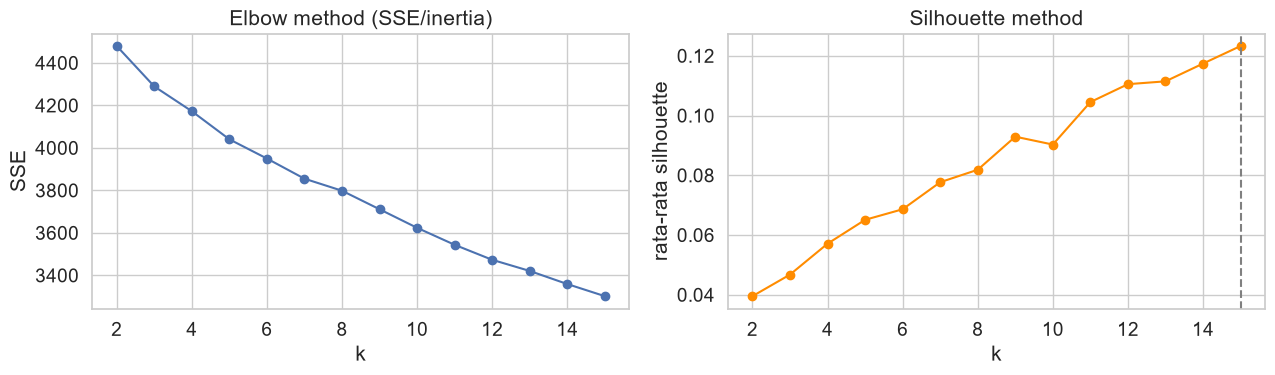

k dengan silhouette tertinggi: 15 | silhouette = 0.123


In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

# Reduksi dimensi (LSA) agar jarak lebih bermakna pada vektor TF-IDF yang jarang
Xs = TruncatedSVD(n_components=50, random_state=RANDOM_STATE).fit_transform(X_demo)
Xs = Xs / np.linalg.norm(Xs, axis=1, keepdims=True).clip(min=1e-9)   # normalisasi → mendekati jarak kosinus

ks = list(range(2, 16))
sse, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    sse.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, sse, "o-"); axes[0].set_title("Elbow method (SSE/inertia)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("SSE")
axes[1].plot(ks, sil, "o-", color="darkorange"); axes[1].set_title("Silhouette method")
axes[1].set_xlabel("k"); axes[1].set_ylabel("rata-rata silhouette")
best_k = ks[int(np.argmax(sil))]
axes[1].axvline(best_k, ls="--", color="gray")
plt.tight_layout(); plt.show()
print("k dengan silhouette tertinggi:", best_k, "| silhouette = %.3f" % max(sil))

In [26]:
# Melihat isi klaster pada k terpilih: kata dengan rata-rata TF-IDF tertinggi per klaster
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
terms = np.array(tfidf_demo.get_feature_names_out())
for c in range(best_k):
    idx = np.where(km.labels_ == c)[0]
    mean_w = np.asarray(X_demo[idx].mean(axis=0)).ravel()
    share_neg = (df.loc[idx, "label"] == "negative").mean()
    print(f"Klaster {c} (n={len(idx)}, negative={share_neg:.0%}):", ", ".join(terms[mean_w.argsort()[::-1][:8]]))

Klaster 0 (n=203, negative=82%): mahal, harga, ongkir, murah, barang, tidak, beli, biaya
Klaster 1 (n=980, negative=35%): cepat, kirim, layan, barang, pesan, gojek, diskon, ramah
Klaster 2 (n=321, negative=74%): nya, tidak, banget, kirim, driver, barang, aplikasi, apk
Klaster 3 (n=275, negative=12%): bagus, aplikasi, layan, banget, nya, cepat, barang, murah
Klaster 4 (n=595, negative=75%): banget, ya, drivernya, apk, buka, bayar, susah, tolong
Klaster 5 (n=203, negative=60%): tokopedia, tidak, belanja, senang, mantab, aplikasi, transaksi, banget
Klaster 6 (n=275, negative=37%): shopee, belanja, tidak, barang, puas, aplikasi, kecewa, the
Klaster 7 (n=287, negative=9%): mudah, belanja, online, cepat, aplikasi, aman, nyaman, suka
Klaster 8 (n=156, negative=3%): mantap, pokok, shopee, aplikasi, bantu, bos, gojek, tokopedia
Klaster 9 (n=562, negative=94%): driver, susah, dapet, tidak, jam, nunggu, banget, cari
Klaster 10 (n=306, negative=77%): aplikasi, tidak, buka, pakai, baik, berat, samp

**Membaca hasil.** Silhouette tertinggi jatuh di ujung rentang yang diuji (k = 15, nilai hanya sekitar 0,12) dan nilainya rendah, sedangkan kurva SSE turun landai tanpa siku yang tegas, sehingga **tidak ada k optimal yang jelas** pada data ini; rentang k perlu diperluas atau dipilih berdasarkan interpretabilitas. Klaster yang terbentuk pada k = 15 cukup bisa ditafsirkan, misalnya klaster 9 (562 ulasan, 94% negative; kata teratas driver, susah, dapet, nunggu, jam, cari) yang paling dekat dengan isu pada artikel Bagian 0, klaster 14 (iklan mengganggu, 88% negative), dan klaster 0 (harga dan ongkir). Ini hanya demonstrasi; klaster berasal dari K-means pada representasi TF-IDF yang direduksi dan tidak diverifikasi manual.

### Daftar Referensi (Bagian 6)

- F. Sebastiani (2002), "Machine Learning in Automated Text Categorization", *ACM Computing Surveys* 34(1) (arXiv:cs/0110053). <https://arxiv.org/abs/cs/0110053>
- M. Steinbach, G. Karypis, V. Kumar (2000), "A Comparison of Document Clustering Techniques", KDD Workshop on Text Mining. <https://www.cs.cmu.edu/~dunja/KDDpapers/Steinbach_IR.pdf>
- T. Thinsungnoen dkk. (2015), "The Clustering Validity with Silhouette and Sum of Squared Errors", *Proc. 3rd International Conference on Industrial Application Engineering (ICIAE)*, DOI 10.12792/iciae2015.012. <https://pdfs.semanticscholar.org/8785/b45c92622ebbbffee055aec198190c621b00.pdf>

Nomor halaman pada penjelasan 6.1–6.3 mengikuti urutan halaman pada berkas PDF yang dibaca (bukan nomor halaman jurnal). Salinan PDF ada di folder `refs/`.

---
## Ringkasan Hasil

Ringkasan angka dari hasil di atas (dihitung otomatis):

In [27]:
best_row = results.loc[results["F1"].idxmax()]
print(f"Model terbaik pada data uji (F1 kelas negative): {results['F1'].idxmax()}")
print(f"  accuracy={best_row['Accuracy']:.3f} precision={best_row['Precision']:.3f} recall={best_row['Recall']:.3f} F1={best_row['F1']:.3f} macro-F1={best_row['Macro-F1']:.3f}")
print(f"Jumlah data uji: {len(y_test)} (≈ ±{1.96*np.sqrt(0.5*0.5/len(y_test)):.3f} galat standar kasar pada accuracy)")

Model terbaik pada data uji (F1 kelas negative): Word2Vec(avg) + Logistic Regression
  accuracy=0.912 precision=0.890 recall=0.966 F1=0.926 macro-F1=0.908
Jumlah data uji: 1032 (≈ ±0.031 galat standar kasar pada accuracy)


**Daftar berkas pengumpulan:** `Tugas_Klasifikasi_Teks_Ulasan.ipynb`, folder `data/` (dataset), folder `article/` (artikel Bagian 0), folder `refs/` (makalah Bagian 6), `requirements.txt`, `README.md`.